# Кластеризация



# K-means

Алгоритм можно схематически представить в виде следующих шагов:

1. Инициализируем центры кластеров случайным образом (должно быть задано количество кластеров).
2. Относим точки к соответствующим кластерам (с минимальным расстоянием до их центра).
3. Производится пересчет центров кластеров по формуле центра масс для всех точек, принадлежащих кластеру.
4. Пункты 2-3 повторяются до тех пор пока центры кластеров перестанут меняться (сильно).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
plt.rcParams['figure.figsize'] = [11, 8]

Произведем кластеризацию на случайно сгенерированных значениях.

In [3]:
from sklearn.cluster import KMeans

np.random.seed(123)
X1 = np.random.randn(100,2)
X2 = np.random.randn(100,2) - np.array([10,1])
X3 = np.random.randn(100,2) - np.array([1,10])
X = np.vstack((X1,X2,X3))
y = np.array([1]*100 + [2]*100 + [3]*100)

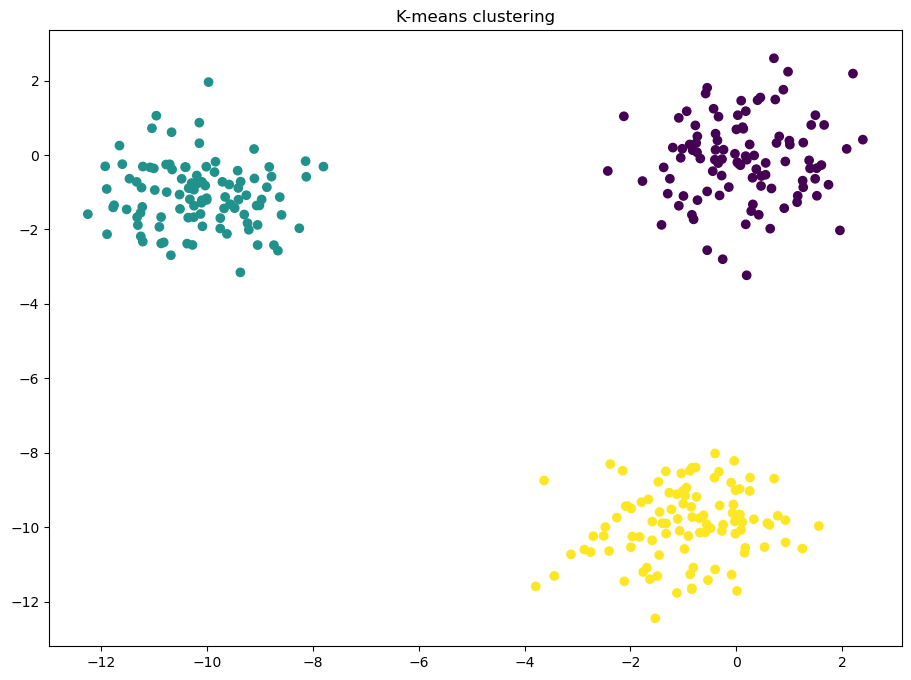

In [4]:
k_means = KMeans(n_clusters = 3)
k_means = k_means.fit(X)
clusters = k_means.predict(X)
plt.scatter(X[:,0], X[:,1], c = clusters)
plt.title('K-means clustering')
plt.show()

Посмотрим, что будет происходить, если мы не угадали с числом кластеров и как меняются метрики.

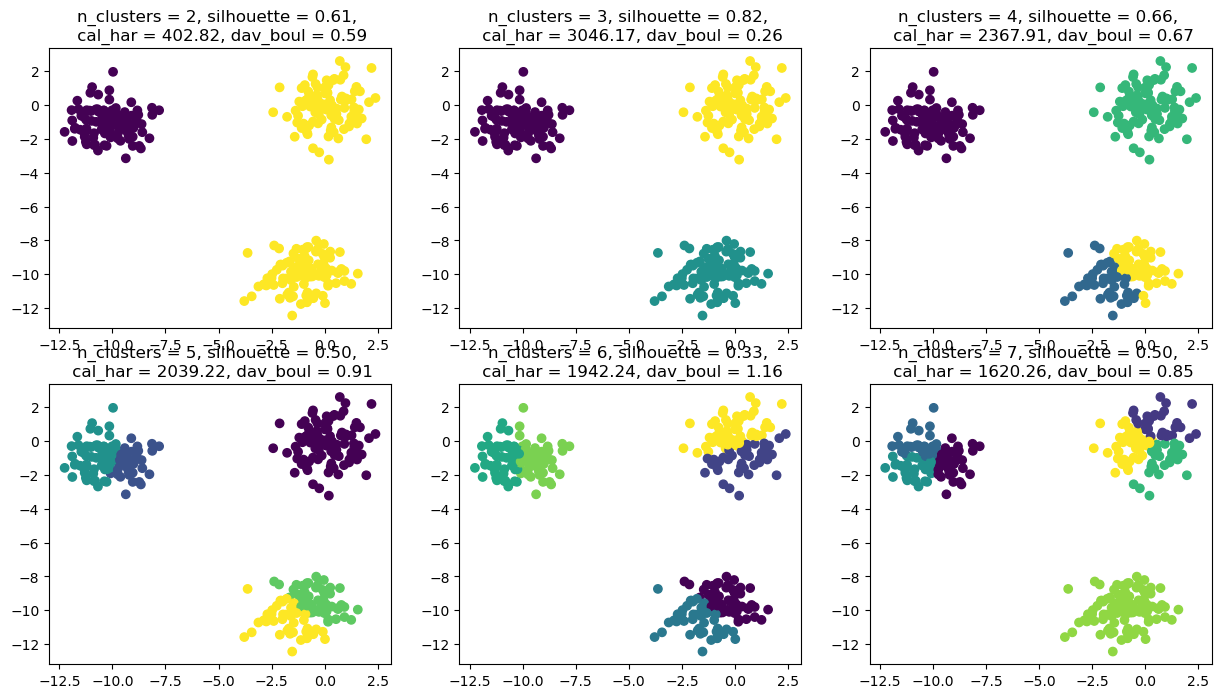

In [5]:
from sklearn import metrics

plt.figure(figsize= (15,8))
for n_c in range(2,8):
    k_means = KMeans(n_clusters = n_c, init = 'random')
    k_means = k_means.fit(X)
    clusters = k_means.predict(X)

    # метрики
    s_sc = metrics.silhouette_score(X, k_means.labels_ , metric='euclidean')
    ch_sc = metrics.calinski_harabasz_score(X, k_means.labels_)
    db_sc = metrics.davies_bouldin_score(X,k_means.labels_)
    
    plt.subplot(2,3,n_c - 1)
    plt.scatter(X[:,0], X[:,1], c = clusters)
    plt.title(f'n_clusters = {n_c}, silhouette = {s_sc:.2f}, \n cal_har = {ch_sc:.2f}, dav_boul = {db_sc:.2f}')

plt.show()

Как мы видим, k-means обязательно пытается отдать каждому кластеру какие-то объекты и, как большинство алгоритмов кластеризации, зависит от заданного числа кластеров. Есть огромное количество вариаций, как выбирать количество кластеров автоматически — например, ввести вероятностный подход к выбору числа кластеров, но данные методы мы не будем рассматривать в этом курсе. 

**Рассмотрите как меняются метрики. Опиши полученные результаты.**

**Вывод:**

При рассмотрении графиков кластеризации, с различными заданными количествами кластеров, можно наблюдать, что не смотря, на четкое разделение наблюдений, k-means делит данные на то количество групп, которое задается алгоритмом, даже если оно не подходит для разделения данных. Как можно заметить наибольшее значение метрик silhouette и cal_har имеет именно распределение на 3 кластера, которое является наиболее подходящим для данных, соответсвенно делаем вывод о том, что распределние на наиболее оптимальное количество кластеров будет сопровождаться наибольшими значениями этих метрик. А метрика dav_boul наоборот имеет наименьшее значение, при самом оптимальном значении количества кластеров. Таким образом в дальнейшем при выборе оптимального количества кластеров для распределения данных, мы сможем ориентироваться на величины данных метрик.

Одним из главных недостатков k-means является случайная инициализация центров кластеров, что может привести к различным результатам кластеризации.

Главным же достоинством является скорость алгоритма. На каждой итерации требуется пересчет только расстояний до центров кластеров.


[Визуализация работы K-Means](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/)

**Проведите аналогичную кластеризацию, но произведите инициализацию центра с помощью `k-means++`**

Инициализируем количество центров с помощью k-means++.

n_init = 10 - означает, что мы инициализируем количество центров для кластеров 10 раз и берем усредненное значение.

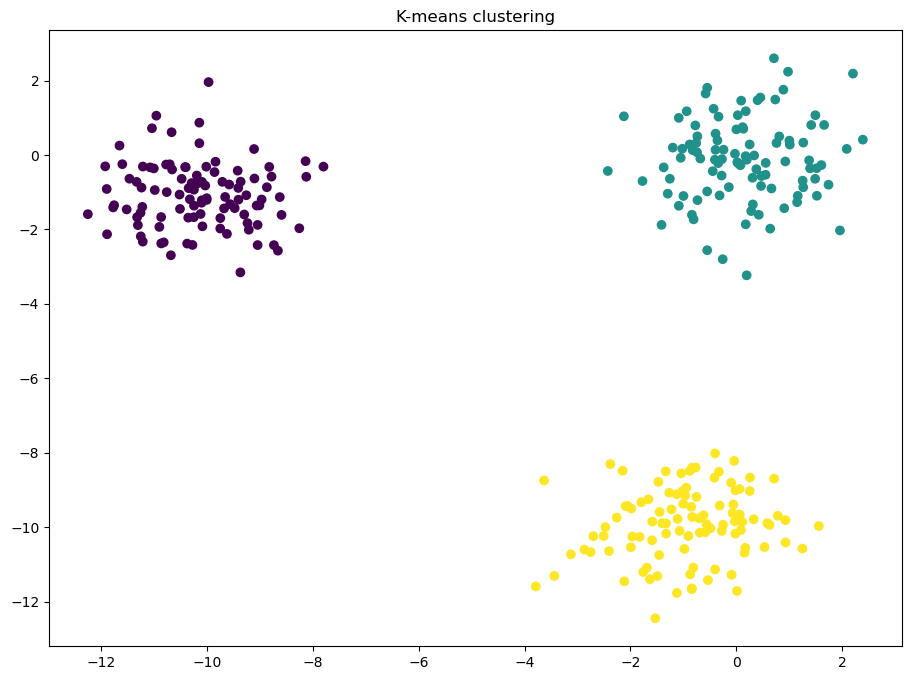

In [6]:
k_means = KMeans(init = "k-means++", n_clusters = 3, n_init = 10)
k_means = k_means.fit(X)
clusters = k_means.predict(X)
plt.scatter(X[:,0], X[:,1], c = clusters)
plt.title('K-means clustering')
plt.show()

Как можно заметить на графике, при инициализации центров для кластеров, мы также получили отличные результаты. 

# DBSCAN

(Density-based spatial clustering of applications with noise)

Это алгоритм, основанный на плотности — если дан набор объектов в некотором пространстве, алгоритм группирует вместе объекты, которые расположены близко и помечает как выбросы (шум) объекты, которые находятся в областях с малой плотностью (ближайшие соседи которых лежат далеко).

Алгоритм имеет два основных гиперпараметра:
1. `eps` &mdash; радиус рассматриваемой окрестности
2. `min_samples` &mdash; число соседей в окрестности

Для выполнения кластеризации DBSCAN точки делятся на основные точки, достижимые по плотности точки и выпадающие следующим образом:

- Точка $p$ является основной точкой, если по меньшей мере `min_samples` точек находятся на расстоянии, не превосходящем 
`eps` от неё. Говорят, что эти точки достижимы прямо из $p$.

-  Точка $q$ прямо достижима из $p$, если точка $q$ находится на расстоянии, не большем `eps`, от точки $p$, и $p$ — основная точка.
Точка $q$ достижима из $p$, если имеется путь 
$p_1,…,p_n$ где $p_1=p$ и $p_n=q$ , а каждая точка $p_{i+1}$ достижима прямо из $p_i$ (все точки на пути должны быть основными, за исключением $q$).

Все точки, не достижимые из основных точек, считаются шумом.

Теперь, если $p$ является основной точкой, то она формирует кластер вместе со всеми точками (основными или неосновными), достижимыми из этой точки. Каждый кластер содержит по меньшей мере одну основную точку. Неосновные точки могут быть частью кластера, но они формируют его «край», поскольку не могут быть использованы для достижения других точек.



Рассмотрим диаграмму, параметр `min_samples`=4.

Точка $A$ и другие красные точки являются основными точками, поскольку область с радиусом 
`eps` , окружающая эти точки, содержит по меньшей мере 4 точки (включая саму точку). Поскольку все они достижимы друг из друга, точки образуют один кластер. Точки $B$ и $C$ основными не являются, но достижимы из $A$ (через другие основные точки), и также принадлежат кластеру. Точка $N$ является точкой шума, она не является ни основной точкой, ни доступной прямо.

<p><a href="https://commons.wikimedia.org/wiki/File:DBSCAN-Illustration.svg#/media/Файл:DBSCAN-Illustration.svg"><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/af/DBSCAN-Illustration.svg/1200px-DBSCAN-Illustration.svg.png" alt="DBSCAN-Illustration.svg" width="450" height="450"> </a><br>Автор: <a href="//commons.wikimedia.org/wiki/User:Chire" title="User:Chire">Chire</a> &mdash; <span class="int-own-work" lang="ru">собственная работа</span>, <a href="https://creativecommons.org/licenses/by-sa/3.0" title="Creative Commons Attribution-Share Alike 3.0">CC BY-SA 3.0</a>

Посмотрим на результаты кластеризации при разном выборе параметров `eps` и `min_samples`.

Шумовые точки помечаются -1

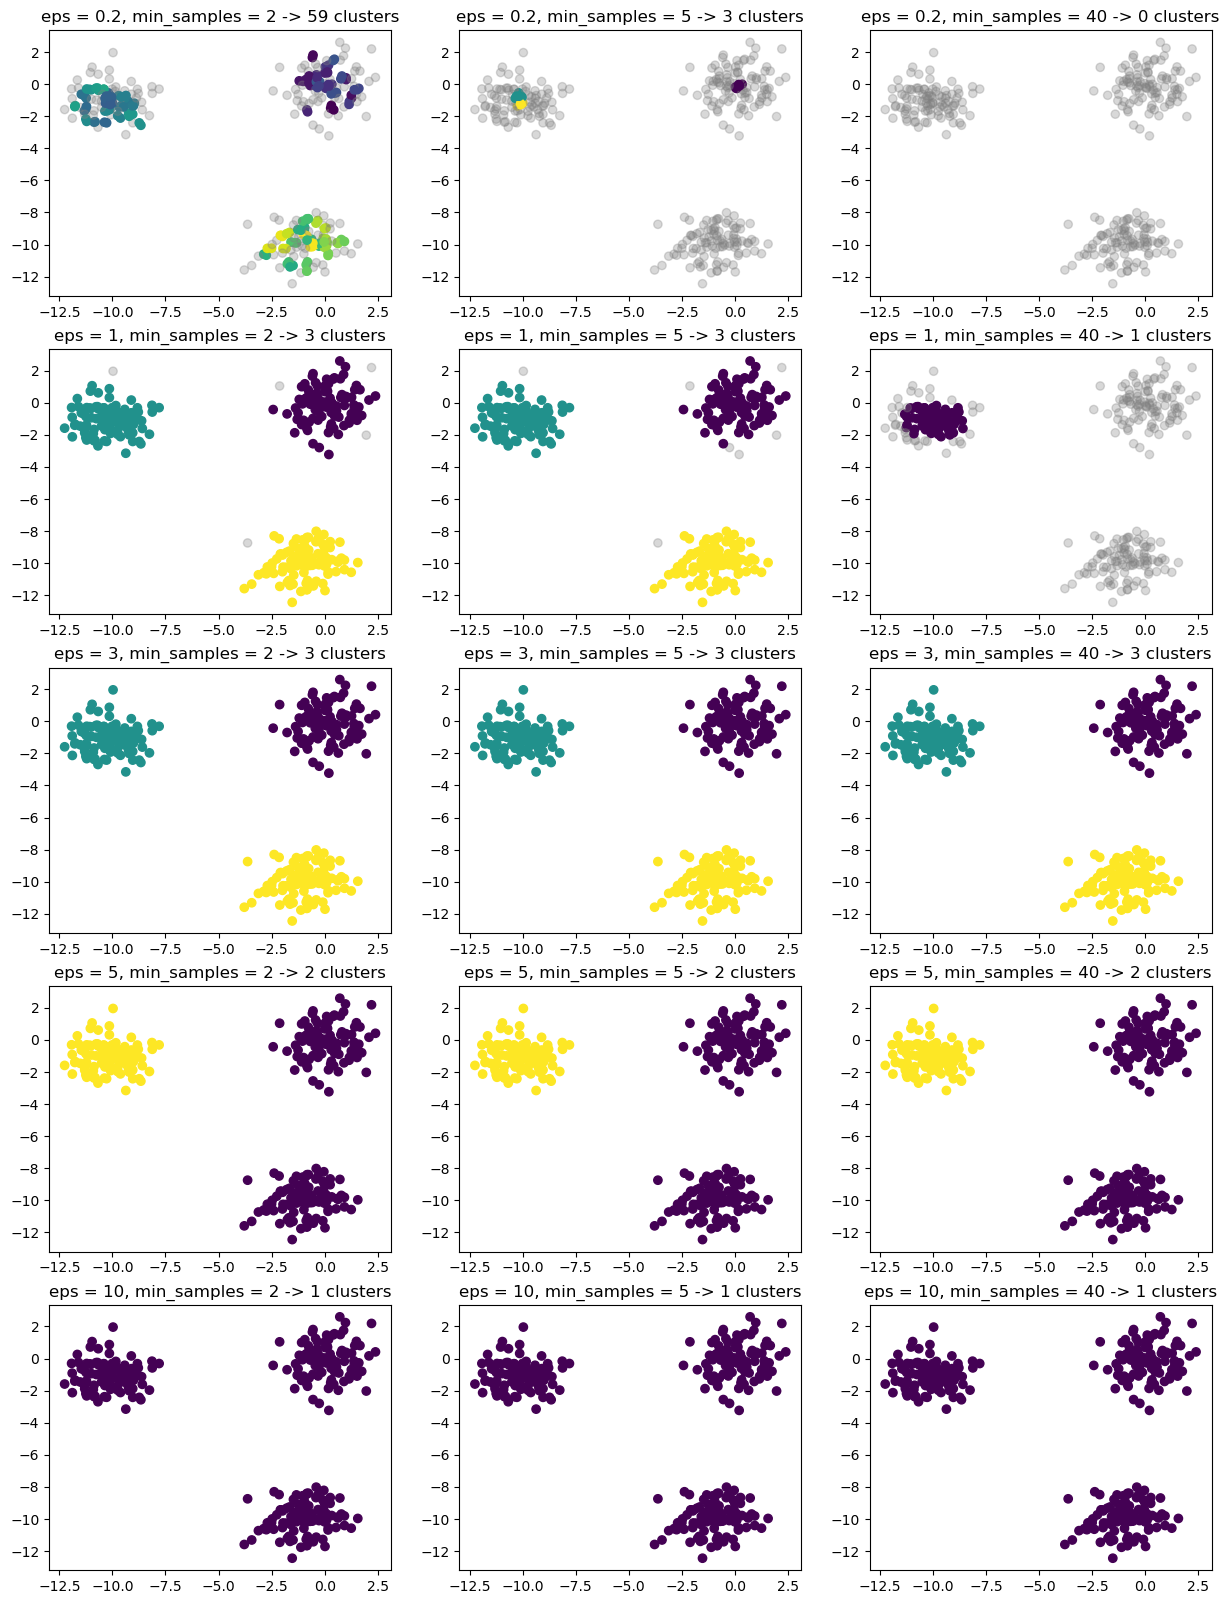

In [7]:
from sklearn.cluster import DBSCAN
import matplotlib as mpl

def get_colors(clusters):
  n_clusters = len(np.unique(clusters[clusters != -1]))
  
  palette = mpl.colormaps['viridis'].resampled(n_clusters)(np.linspace(0, 1, n_clusters))
  colors = np.zeros((clusters.shape[0], 4))
  colors[clusters != -1] = palette[clusters[clusters != -1]]
  
  #Шум будет серо-прозрачным
  colors[clusters == -1] = [0.5, 0.5, 0.5, 0.3]
  
  return colors

plt.figure(figsize= (15,20))
i = 1

for e in [0.2, 1, 3, 5, 10]:
    for samples in [2, 5, 40]:
        dbscan = DBSCAN(eps=e, min_samples=samples)
        clusters = dbscan.fit_predict(X)

        n_clusters = len(np.unique(clusters[clusters != -1]))
        colors = get_colors(clusters)
        
        plt.subplot(5, 3, i)

        plt.scatter(X[:,0], X[:,1], c=colors)
        plt.title('eps = {}, min_samples = {} -> {} clusters'.format(e, samples, n_clusters))
        i += 1


plt.show()

[Визуализация работы DBSCAN](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/)


При анализе влияния параметров на кластеризацию методом DBSCAN, можно отметить, что наилучшие распределения мы получили при eps (радиус окрестности, который определяет, какие точки считаются соседними) = 3 и при min_samples ( определяет будут ли относиться точки, находящиеся в менее плотно-рагруженных местах, к кластеру, при увеличении параметра, менее плотные точки считаются шумом) = 2, 5, 40.

При слишком маленьком eps и большом min_samples, мы получили слишком много шумов.

При слишком большом eps, все кластеры объединились в один.

Результаты работы методов на других датасетах:

Выводим распределение данных, без кластеризации

In [8]:
from sklearn.datasets import make_moons, make_circles

In [9]:
X, y = make_moons(n_samples=500, noise=0.1)

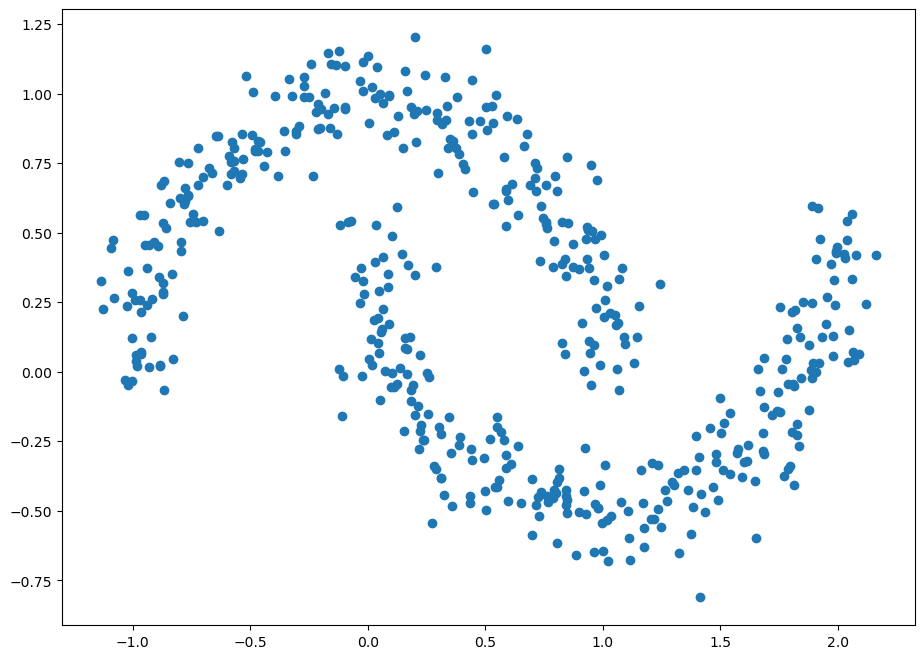

In [10]:
plt.scatter(X[:,0], X[:,1])
plt.show()

Проведем кластеризацию методом k-means 

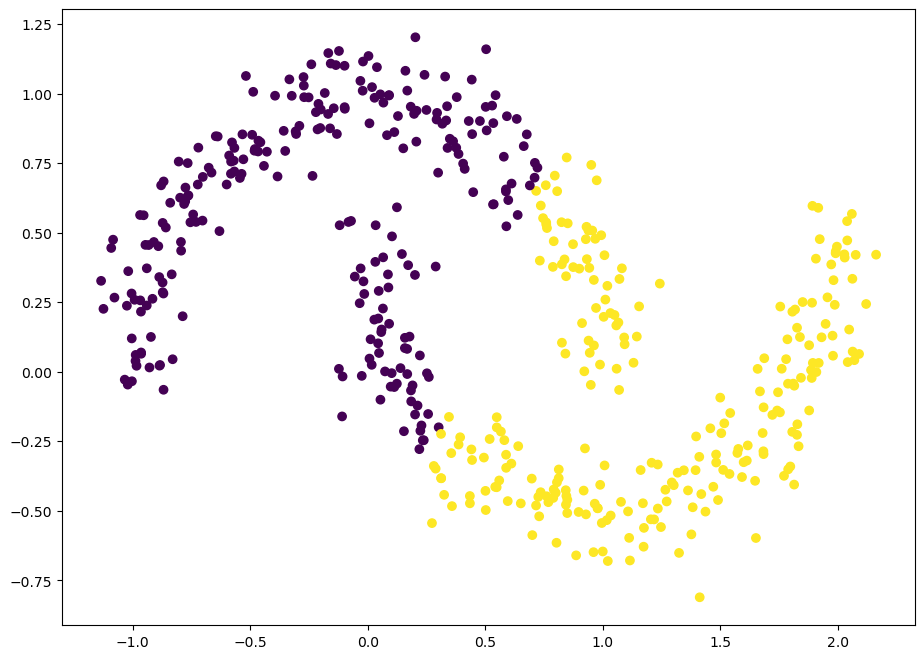

In [11]:
k_means = KMeans(n_clusters = 2)
k_means = k_means.fit(X)
clusters = k_means.predict(X)

colors = get_colors(clusters)
plt.scatter(X[:,0], X[:,1], c=colors)
plt.show()

Как можно заметить, не смотря на заданные 2 кластера, данные распределены на них неверно.

Кластеризация методом DBSCAN 

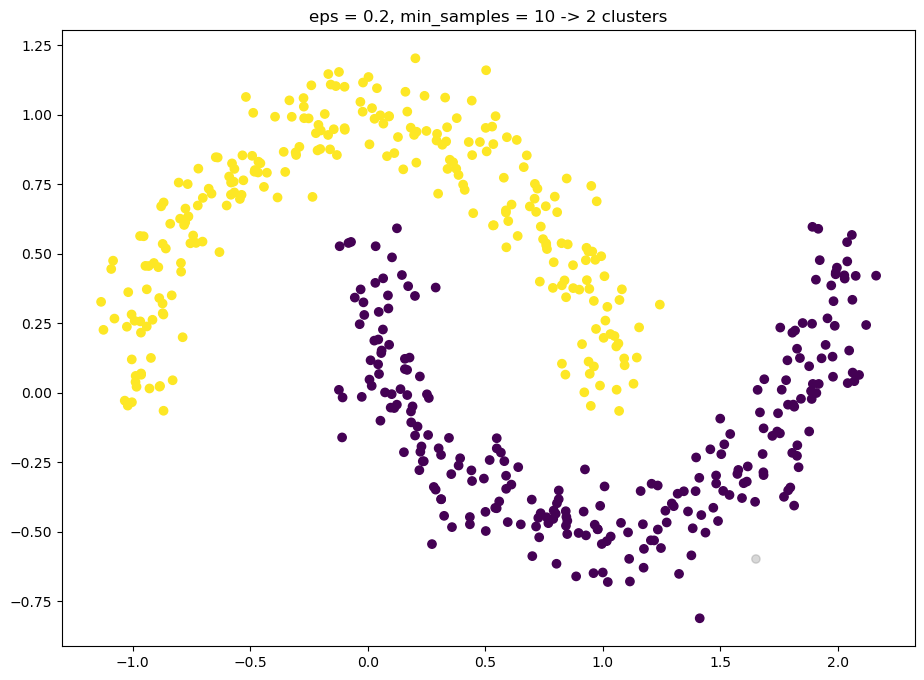

In [12]:
dbscan = DBSCAN(eps=0.2, min_samples=10)
clusters = dbscan.fit_predict(X)

colors = get_colors(clusters)
plt.scatter(X[:,0], X[:,1], c=colors)
plt.title('eps = {}, min_samples = {} -> {} clusters'.format(dbscan.eps, dbscan.min_samples, len(np.unique(clusters[clusters != -1]))))
plt.show()

При кластеризации данных make_moons были выполнены и визуализированы методы k-means и DBSCAN. Метод  DBSCAN справился с задачей кластеризации, что подтвержает график, а метод k-means показал неверное распределение. Данные различия, при одинаковом количестве кластеров и одинаковых данных, могут быть вызваны тем, что DBSCAN имеет параметр, определяющий радиус между точками, соответственно их распределение на кластеры производится методом присоединения ближайших точек - соседей. В то время как метод  k-means, определяет кластеры на основе расположения центров кластеров и расстрояния точек от них, в данном случае, такой метод будет захватывать в кластер точки другого кластера.

In [13]:
X, y = make_circles(n_samples=500, noise=0.05, factor=0.5)

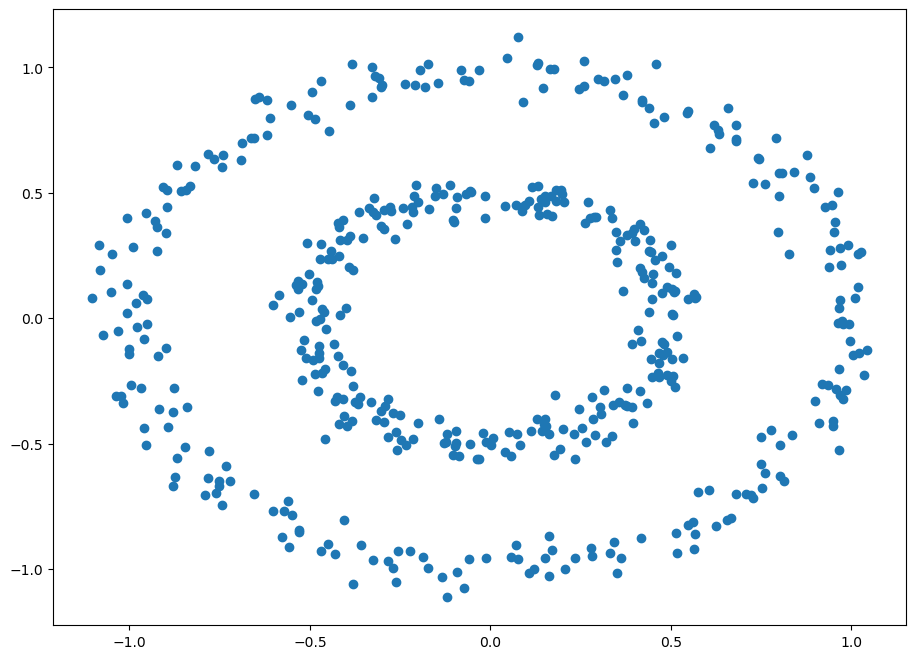

In [14]:
plt.scatter(X[:,0], X[:,1])
plt.show()

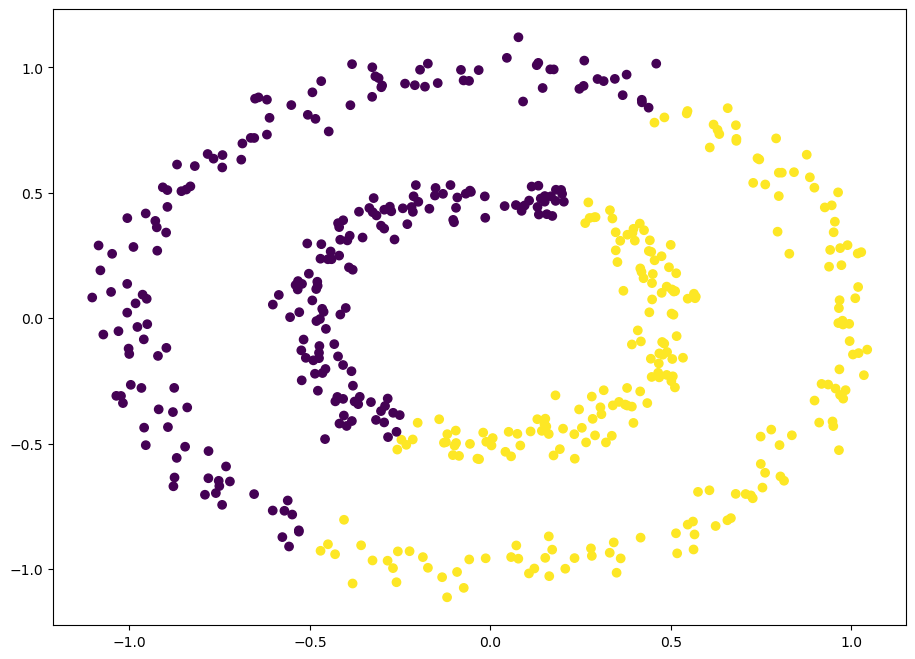

In [15]:
k_means = KMeans(n_clusters = 2)
k_means = k_means.fit(X)
clusters = k_means.predict(X)
plt.scatter(X[:,0], X[:,1], c=clusters)
plt.show()

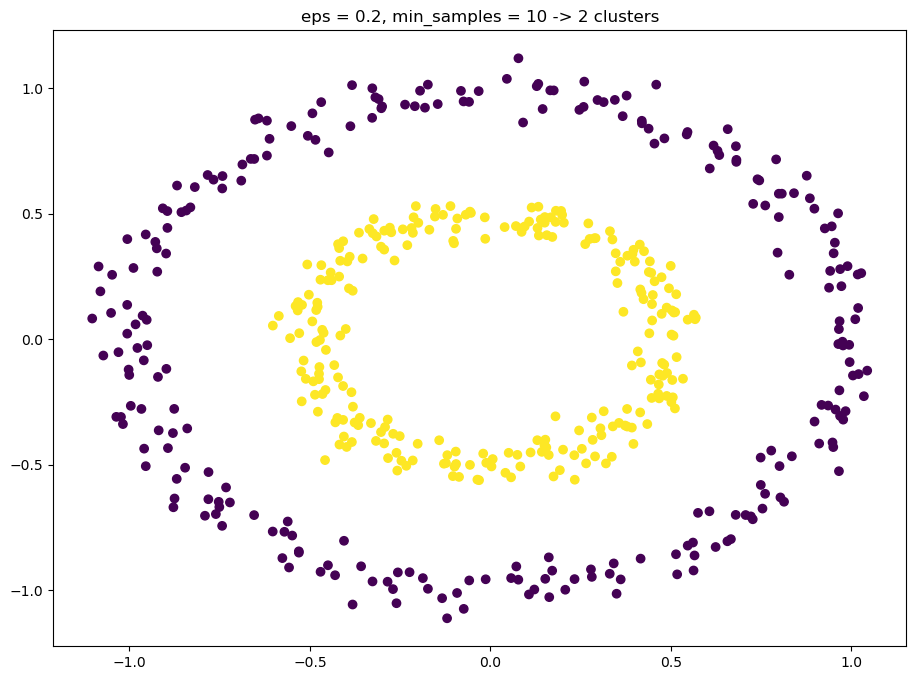

In [16]:
dbscan = DBSCAN(eps=0.2, min_samples=10)
clusters = dbscan.fit_predict(X)
colors = get_colors(clusters)
plt.scatter(X[:,0], X[:,1], c=colors)
plt.title('eps = {}, min_samples = {} -> {} clusters'.format(dbscan.eps, dbscan.min_samples, len(np.unique(clusters[clusters != -1]))))
plt.show()

При кластеризации данных make_circles мы видим такой же результат двух методов, как и с предыдущими данными, за счет особенности формирования кластеров в методе DBSCAN, то есть присоединения ближайших точек, был получен хороший результат распредедления, а метод k-means не справился с кластеризацией таких данных, по той же причине, что была описана раньше.

k-Means выделяет только выпуклые кластеры, сходного размера. Не очень хорошо работает с шумными данными. Хуже видит аномалии. С другой стороны, k-means лучше справляется с большими данными и размерностью, а также разреженными данными с переменной плотностью (DBSCAN скорее относит разные плотности к разным кластерам).

# Иерархическая кластеризация

Другим вариантом к построению кластеров является иерархический подход, в котором алгоритм жадным образом строит кластеры. Существует два варианта иерархической кластеризации:

1. аггломеративная, в которой алгоритм на каждой итерации объединяет два меньших кластера в один
2. дивизивная, в которой алгоритм на каждой итерации разбивает один кластер на два более мелких

Мы рассмотрим аггломеративный подход к кластеризации.

Посмотрим на иерархическую кластеризацию на примере:


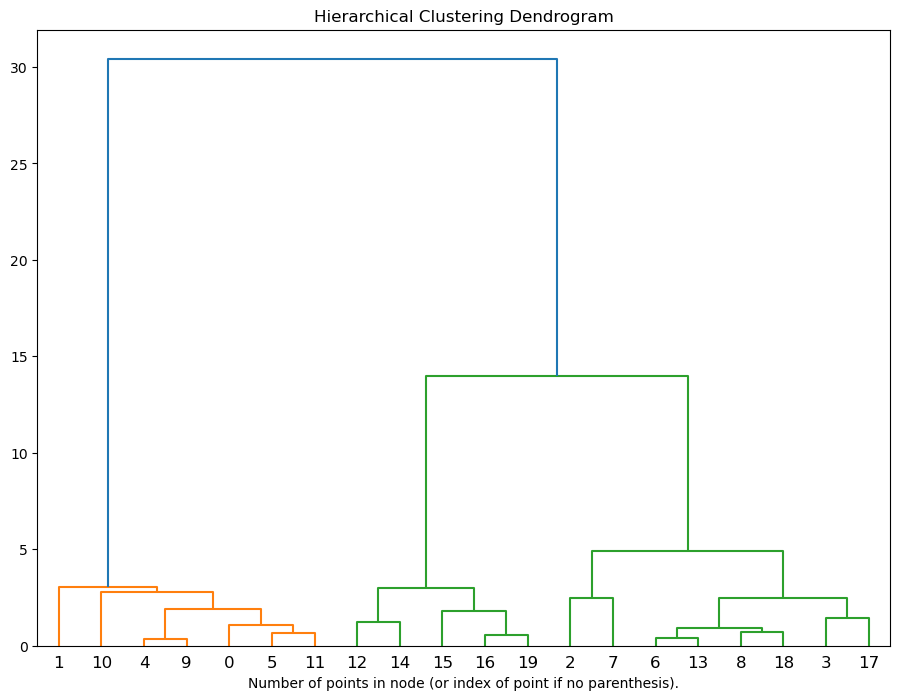

In [17]:
import numpy as np

from sklearn.datasets import make_blobs
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

X, _ = make_blobs(n_samples=20, random_state=146)

# setting distance_threshold=0 ensures we compute the full tree.
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None)

model = model.fit(X)
plt.title("Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(model, truncate_mode="level", p=5)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

Если нет каких-то специализированных условий (например, известно, что кластеров должно быть не более $K$), то число кластеров можно выбирать по резкому скачку дендрограммы. Кроме того, в некоторых задачах важно понимать, для чего делается кластеризация и доменную область задачи — исходя из этого можно сильно сократить искомое количество кластеров.

**Опишите полученные результаты**

**Вывод:**

Как можно заметить на графике, имеющиеся данные разделились на 3 примерно одинаковые группы, каждая из которых была получена путем объединения двух предыдущих. Оптимальное количество кластеров для таких данных - 3. Наблюдая визуализацию именно деление на три группы наиболее равномерно. Деление на две группы приводит к тому, что 1 кластер включает в себя в двое больше наблюдений, чем 2-ой.

# Сравнение работы алгоритмов

Сгенерируем кластеры разной формы и посмотрим на результаты работы алгоритмов

Automatically created module for IPython interactive environment


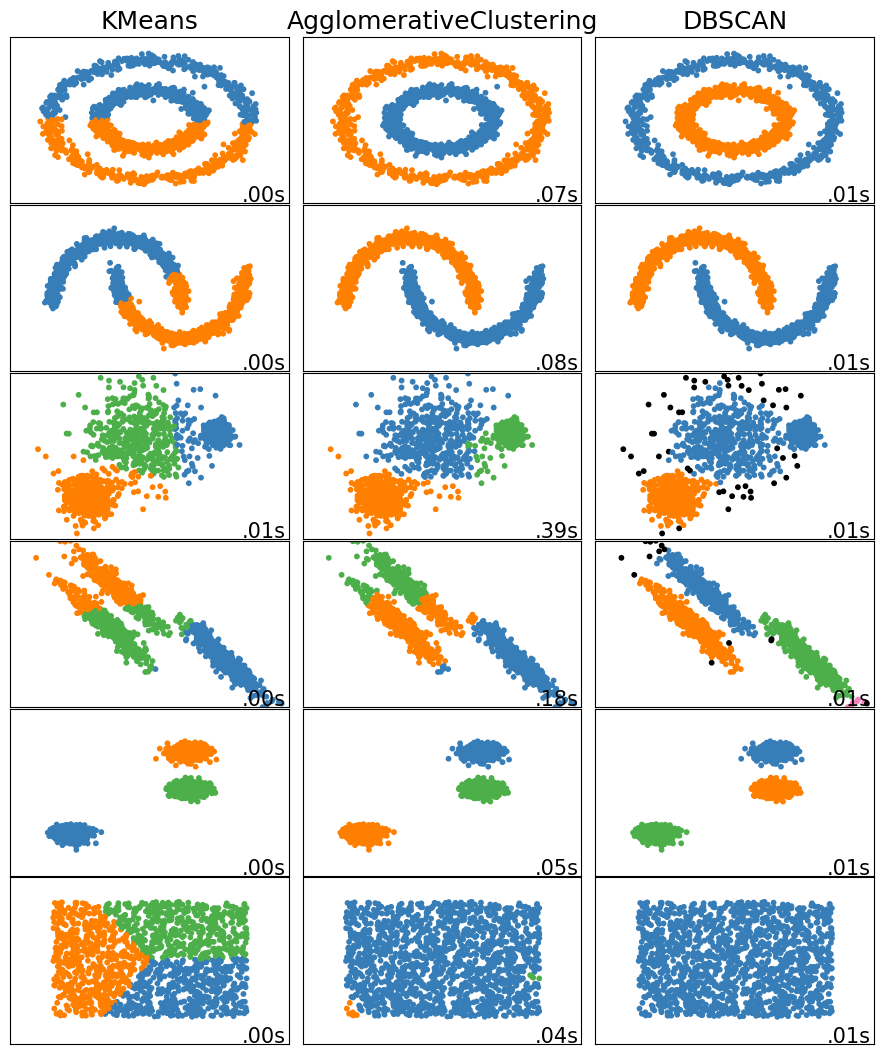

In [18]:
print(__doc__)

import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice
warnings.simplefilter('ignore')

np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=.5,
                                      noise=.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(n_samples=n_samples,
                             cluster_std=[1.0, 2.5, 0.5],
                             random_state=random_state)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(3 * 2 + 3, 10.5))
plt.subplots_adjust(left=.02, right=.98, bottom=.001, top=.96, wspace=.05,
                    hspace=.01)

plot_num = 1

default_base = {'quantile': .3,
                'eps': .3,
                'damping': .9,
                'preference': -200,
                'n_neighbors': 10,
                'n_clusters': 3,
                'min_samples': 20,
                'xi': 0.05,
                'min_cluster_size': 0.1}

datasets = [
    (noisy_circles, {'damping': .77, 'preference': -240,
                     'quantile': .2, 'n_clusters': 2,
                     'min_samples': 20, 'xi': 0.25}),
    (noisy_moons, {'damping': .75, 'preference': -220, 'n_clusters': 2}),
    (varied, {'eps': .18, 'n_neighbors': 2,
              'min_samples': 5, 'xi': 0.035, 'min_cluster_size': .2}),
    (aniso, {'eps': .15, 'n_neighbors': 2,
             'min_samples': 20, 'xi': 0.1, 'min_cluster_size': .2}),
    (blobs, {}),
    (no_structure, {})]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)
    connectivity = kneighbors_graph(
        X, n_neighbors=params['n_neighbors'], include_self=False)
    
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    # ============
    # Create cluster objects
    # ============
    
    k_means = cluster.KMeans(n_clusters=params['n_clusters'])


    dbscan = cluster.DBSCAN(eps=params['eps'])
    
    average_linkage =  cluster.AgglomerativeClustering(
        linkage="average", 
        n_clusters=params['n_clusters'], connectivity=connectivity)
    

    clustering_algorithms = (
        ('KMeans', k_means),
        ('AgglomerativeClustering', average_linkage),
        ('DBSCAN', dbscan),
    )

    for name, algorithm in clustering_algorithms:
        t0 = time.time()

        algorithm.fit(X)

        t1 = time.time()
        if hasattr(algorithm, 'labels_'):
            y_pred = algorithm.labels_.astype(np.int64)
        else:
            y_pred = algorithm.predict(X)

        plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(list(islice(cycle(['#377eb8', '#ff7f00', '#4daf4a',
                                             '#f781bf', '#a65628', '#984ea3',
                                             '#999999', '#e41a1c', '#dede00']),
                                      int(max(y_pred) + 1))))
        # add black color for outliers (if any)
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])

        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plt.text(.99, .01, ('%.2fs' % (t1 - t0)).lstrip('0'),
                 transform=plt.gca().transAxes, size=15,
                 horizontalalignment='right')
        plot_num += 1

plt.show()

Рассмотрев кластеризацию тремя методами разных форм данных (кластеров). Можно сказать о том, что с кластеризацией певрого и второго типа данных справились методы DBSCAN и аггломеративная кластеризация, но не справился k-means. С кластеризацией 5 типа данных справились все методы. Наилучшие результаты по 3-му типу данных получены по k-means и аггломеративной кластеризации. С типом данных 4 справился только DBSCAN.

Можем сделать вывод о том, что для работы с аномальными данными точно не подойдет метод k-means, так как он определяет кластеры примерно одного размера, но для кластеризации данных разной плотности метод покажет хорошие результаты. Для данных с выбросами и аномалиями лучше всего подойдет метод DBSCAN. Агломеративная кластеризация неплохо справляется почти со всеми типами данных.

# Примеры кластеризации методами без заданного количества кластеров

- Affinity Propagation
- OPTICS
- Mean shift


In [19]:
import numpy as np
from sklearn.datasets import make_blobs

# Генерация случайных данных
# Здесь мы создаем набор данных с 300 образцами, 2 признаками и 5 центрами (кластерами).
X, _ = make_blobs(n_samples=300, centers=5, cluster_std=0.60, random_state=0)


## Affinity Propagation

Параметр `preference` контролирует, сколько образцов (exemplars) будет использоваться для описания набора данных. По сути, он определяет, насколько "предпочтительным" является выбор объекта в качестве образца. Более высокое значение preference приводит к большему числу кластеров, так как алгоритм будет стремиться выбрать больше образцов. И наоборот, более низкое значение preference приводит к меньшему числу кластеров, так как алгоритм будет выбирать меньше образцов.

Значение preference может быть задано либо одним числом для всех объектов, либо массивом чисел для каждого объекта в отдельности. По умолчанию preference устанавливается равным медиане попарных сходств между объектами, что обычно приводит к разумному числу кластеров.

Параметр `damping factor` (коэффициент затухания) используется для сглаживания сообщений ответственности и доступности при их обновлении на каждой итерации алгоритма. Это помогает избежать численных осцилляций и нестабильности в процессе обмена сообщениями.

Damping factor принимает значения между 0.5 и 1. Более высокое значение приводит к более сильному сглаживанию сообщений и замедляет сходимость алгоритма. Рекомендуемое значение damping factor составляет около 0.5-0.9. По умолчанию оно равно 0.5.


In [20]:
%%time

from sklearn.cluster import AffinityPropagation
from sklearn.metrics import calinski_harabasz_score

affinity_propagation = AffinityPropagation(random_state=0, damping=0.7, preference=-50)
affinity_propagation.fit(X)
labels = affinity_propagation.labels_

n_clusters = len(np.unique(labels))

if n_clusters > 1:
    ch_score = calinski_harabasz_score(X, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")
    
print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 5
Оценка Калинского-Харабаша: 2806.19
CPU times: user 22.2 ms, sys: 1.89 ms, total: 24.1 ms
Wall time: 24.6 ms


## OPTICS

In [21]:
%%time

import numpy as np
from sklearn.cluster import OPTICS

optics = OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05)
optics.fit(X)

labels = optics.labels_

# Определите количество кластеров (без учета шумовых точек, которые помечаются как -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

if n_clusters > 1:
    ch_score = calinski_harabasz_score(X, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")

print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 5
Оценка Калинского-Харабаша: 1944.34
CPU times: user 214 ms, sys: 2.52 ms, total: 216 ms
Wall time: 228 ms


## Mean Shift 

In [22]:
%%time

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

bandwidth = estimate_bandwidth(X_scaled, quantile=0.2, n_samples=500)

ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
clusters = ms.fit_predict(X_scaled)

n_clusters_ = len(np.unique(clusters))

if n_clusters > 1:
    ch_score = calinski_harabasz_score(X, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")

print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 5
Оценка Калинского-Харабаша: 1944.34
CPU times: user 38.8 ms, sys: 0 ns, total: 38.8 ms
Wall time: 37.1 ms


**Опишите полученные результаты**

**Вывод:**

По результатам всех трех методов, полученное значение оптимального количества кластеров равно 5. 
На основе метрик оценки, можно сделать вывод о том, что наилучший метод для кластеризации данных - Affinity Propagation, так как оценка Калинского-Харабаша у него является наибольшей среди трех представленных методов.

# Задание

Файл `customer_segmentation.csv` содержит данные о клиентах, которые могут быть использованы для сегментации клиентов на основе их демографических, поведенческих и финансовых характеристик. 

Этот набор данных содержит 29 признаков и 2240 записей.

**1. Идентификация и демографические данные клиента**

- **ID**: Уникальный идентификатор клиента.
- **Year_Birth**: Год рождения клиента.
- **Education**: Уровень образования клиента.
- **Marital_Status**: Семейное положение клиента.
- **Income**: Годовой доход клиента.
- **Kidhome**: Количество детей (возрастом до 12 лет) в семье.
- **Teenhome**: Количество подростков (от 13 до 18 лет) в семье.
- **Dt_Customer**: Дата регистрации клиента в компании.

**2. Покупательское поведение**

**2.1. Затраты на продукты (денежные траты)**

- **MntWines**: Сумма, потраченная на покупку вина за последние два года.
- **MntFruits**: Сумма, потраченная на покупку фруктов за последние два года.
- **MntMeatProducts**: Сумма, потраченная на покупку мясных продуктов за последние два года.
- **MntFishProducts**: Сумма, потраченная на покупку рыбы и морепродуктов за последние два года.
- **MntSweetProducts**: Сумма, потраченная на покупку сладостей за последние два года.
- **MntGoldProds**: Сумма, потраченная на покупку золотых изделий за последние два года.

**2.2. Частота и каналы покупок**

- **NumDealsPurchases**: Количество покупок по акции или скидке.
- **NumWebPurchases**: Количество покупок, совершенных через веб-сайт компании.
- **NumCatalogPurchases**: Количество покупок, совершенных по каталогу.
- **NumStorePurchases**: Количество покупок, совершенных напрямую в магазине.
- **NumWebVisitsMonth**: Количество посещений веб-сайта компании за последний месяц.
- **Recency**: Количество дней, прошедших с момента последней покупки клиента.

**3. Отклик на маркетинговые кампании**

- **AcceptedCmp1**: Принял ли клиент предложение в рамках кампании 1 (1 – да, 0 – нет).
- **AcceptedCmp2**: Принял ли клиент предложение в рамках кампании 2.
- **AcceptedCmp3**: Принял ли клиент предложение в рамках кампании 3.
- **AcceptedCmp4**: Принял ли клиент предложение в рамках кампании 4.
- **AcceptedCmp5**: Принял ли клиент предложение в рамках кампании 5.
- **Response**: Принял ли клиент предложение в рамках последней кампании.


**4. Жалобы и удовлетворенность**

- **Complain**: Подавал ли клиент жалобу за последние два года (1 – да, 0 – нет).

**5. Постоянные параметры компании**

- **Z_CostContact**: Стоимость контакта с клиентом по маркетинговой кампании (постоянная величина для всех клиентов).
- **Z_Revenue**: Стандартная величина выручки с клиента (постоянная величина для всех клиентов).

#### Произведите кластеризацию и проанализуйте результаты с помощью методов:

- Affinity Propagation
- OPTICS
- Mean shift

Сопоставьте полученные результаты, оцените результаты с помощью метрик. Визуализируйте полученные результаты с помощью метода главных компонент.

*Если вычисления занимают много времени, рекомендуется уменьшить объем исходных данных, сократив количество объектов и признаков.*


In [51]:
import pandas as pd
import numpy as np
from factor_analyzer import FactorAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import kagglehub

In [52]:
# Download
df_path = kagglehub.dataset_download("vishakhdapat/customer-segmentation-clustering", path = "customer_segmentation.csv")

In [53]:
# Загрузка данных
df = pd.read_csv(df_path, sep=',')
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


Удалим некоторые колонки неважные для последующего анализа

In [54]:
df = df.drop(columns=["ID","Z_CostContact","Z_Revenue","Dt_Customer"])
#Если хотим из признака формата: день-месяц-год, вытащить значение года или день-месяц:
#df['Dt_Customer'] = [i[-4:] for i in df['Dt_Customer']] - только год будет в столбце признака 
#df['Dt_Customer'] = [i[:-5] for i in df['Dt_Customer']] - месяц и день будут в столбце признака

Проверим на наличие пропусков имеющиеся данные 

In [55]:
missing_counts = df.isnull().sum()
print(missing_counts)

Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Response                0
dtype: int64


Удалим пустые значения, так как они составляют меньше 5% данных.

In [56]:
df = df.dropna()

In [57]:
df

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,1957,Graduation,Single,58138.0,0,0,58,635,88,546,...,10,4,7,0,0,0,0,0,0,1
1,1954,Graduation,Single,46344.0,1,1,38,11,1,6,...,1,2,5,0,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,26,426,49,127,...,2,10,4,0,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,26,11,4,20,...,0,4,6,0,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,94,173,43,118,...,3,6,5,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,Graduation,Married,61223.0,0,1,46,709,43,182,...,3,4,5,0,0,0,0,0,0,0
2236,1946,PhD,Together,64014.0,2,1,56,406,0,30,...,2,5,7,0,0,0,1,0,0,0
2237,1981,Graduation,Divorced,56981.0,0,0,91,908,48,217,...,3,13,6,0,1,0,0,0,0,0
2238,1956,Master,Together,69245.0,0,1,8,428,30,214,...,5,10,3,0,0,0,0,0,0,0


Проведем кодировку категориальных признаков

In [58]:
from sklearn.preprocessing import LabelEncoder
# Create a label encoder object
label_encoder = LabelEncoder()

df = df.copy()
# Transform the 'categories' column
df['Education'] = label_encoder.fit_transform(df['Education'].values)
df['Marital_Status'] = label_encoder.fit_transform(df['Marital_Status'].values)

df

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,1957,2,4,58138.0,0,0,58,635,88,546,...,10,4,7,0,0,0,0,0,0,1
1,1954,2,4,46344.0,1,1,38,11,1,6,...,1,2,5,0,0,0,0,0,0,0
2,1965,2,5,71613.0,0,0,26,426,49,127,...,2,10,4,0,0,0,0,0,0,0
3,1984,2,5,26646.0,1,0,26,11,4,20,...,0,4,6,0,0,0,0,0,0,0
4,1981,4,3,58293.0,1,0,94,173,43,118,...,3,6,5,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,2,3,61223.0,0,1,46,709,43,182,...,3,4,5,0,0,0,0,0,0,0
2236,1946,4,5,64014.0,2,1,56,406,0,30,...,2,5,7,0,0,0,1,0,0,0
2237,1981,2,2,56981.0,0,0,91,908,48,217,...,3,13,6,0,1,0,0,0,0,0
2238,1956,3,5,69245.0,0,1,8,428,30,214,...,5,10,3,0,0,0,0,0,0,0


Выполним стандартизацию данных

Данный шаг часто используется при кластеризации, так как позволяет лучше сравнить и соотвественно объединить в группы данные, которые привидены к единому виду.
При выполнении метода Affinity Propagation  было получено около 2000 кластеров, именно поэтому было принято решение использовать стандартизацию для получения наилучших результатов.

In [59]:
from sklearn.preprocessing import StandardScaler

In [60]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [61]:
df_scaled

array([[-0.98644293, -0.35052725,  0.25421812, ..., -0.11714818,
        -0.09781206,  2.37795178],
       [-1.23680074, -0.35052725,  0.25421812, ..., -0.11714818,
        -0.09781206, -0.42052997],
       [-0.31882209, -0.35052725,  1.18230273, ..., -0.11714818,
        -0.09781206, -0.42052997],
       ...,
       [ 1.01641959, -0.35052725, -1.60195109, ..., -0.11714818,
        -0.09781206, -0.42052997],
       [-1.06989553,  0.53924181,  1.18230273, ..., -0.11714818,
        -0.09781206, -0.42052997],
       [-1.23680074,  1.42901088, -0.67386649, ..., -0.11714818,
        -0.09781206,  2.37795178]], shape=(2216, 25))

## Affinity Propagation

In [91]:
%%time

from sklearn.cluster import AffinityPropagation
from sklearn.metrics import calinski_harabasz_score

affinity_propagation = AffinityPropagation(random_state=0, damping=0.5, preference=-600)
affinity_propagation.fit(df_scaled)
labels = affinity_propagation.labels_

n_clusters = len(np.unique(labels))

if n_clusters > 1:
    ch_score = calinski_harabasz_score(df_scaled, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")
    
print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 15
Оценка Калинского-Харабаша: 159.27
CPU times: user 4.48 s, sys: 114 ms, total: 4.59 s
Wall time: 4.48 s


## OPTICS

In [88]:
%%time

import numpy as np
from sklearn.cluster import OPTICS

optics = OPTICS(min_samples=20, xi=0.05, min_cluster_size=0.02)
optics.fit(df)

labels = optics.labels_

# Определите количество кластеров (без учета шумовых точек, которые помечаются как -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

if n_clusters > 1:
    ch_score = calinski_harabasz_score(df, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")

print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 11
Оценка Калинского-Харабаша: 48.91
CPU times: user 2.87 s, sys: 16.7 ms, total: 2.88 s
Wall time: 1.68 s


## Mean Shift 

In [76]:
%%time

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

bandwidth = estimate_bandwidth(df_scaled, quantile=0.2, n_samples=500)

ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
clusters = ms.fit_predict(df_scaled)

n_clusters_ = len(np.unique(clusters))

if n_clusters > 1:
    ch_score = calinski_harabasz_score(df, labels)
else:
    ch_score = 0
    print("Найден только один кластер, невозможно рассчитать оценку Калинского-Харабаша.")

print(f"Оптимальное количество кластеров: {n_clusters}")
print(f"Оценка Калинского-Харабаша: {ch_score:.2f}")

Оптимальное количество кластеров: 11
Оценка Калинского-Харабаша: 48.91
CPU times: user 573 ms, sys: 4 ms, total: 577 ms
Wall time: 296 ms


После проведения трех методов кластеризации, можем сделать вывод о том, что наилучшим для выбранных данных является метод Affinity Propagation, так как он имеет набольшее значение оценки Калинского-Харабаша, равное 159.27, а методы Mean Shift и OPTICS имеют одинаковые оценки, равные 48.91. На основе выбранного метода - Affinity Propagation, полученное оптимальное количество кластеров 15. Параметры для данного метода, также были подобраны на основе значения оценки Калинского-Харабаша, а также на основе "адекватности" разделения количества наблюдений на определенное количество кластеров. Можно сказать, что 15 кластеров полученных с помощью Affinity Propagation более четкие.

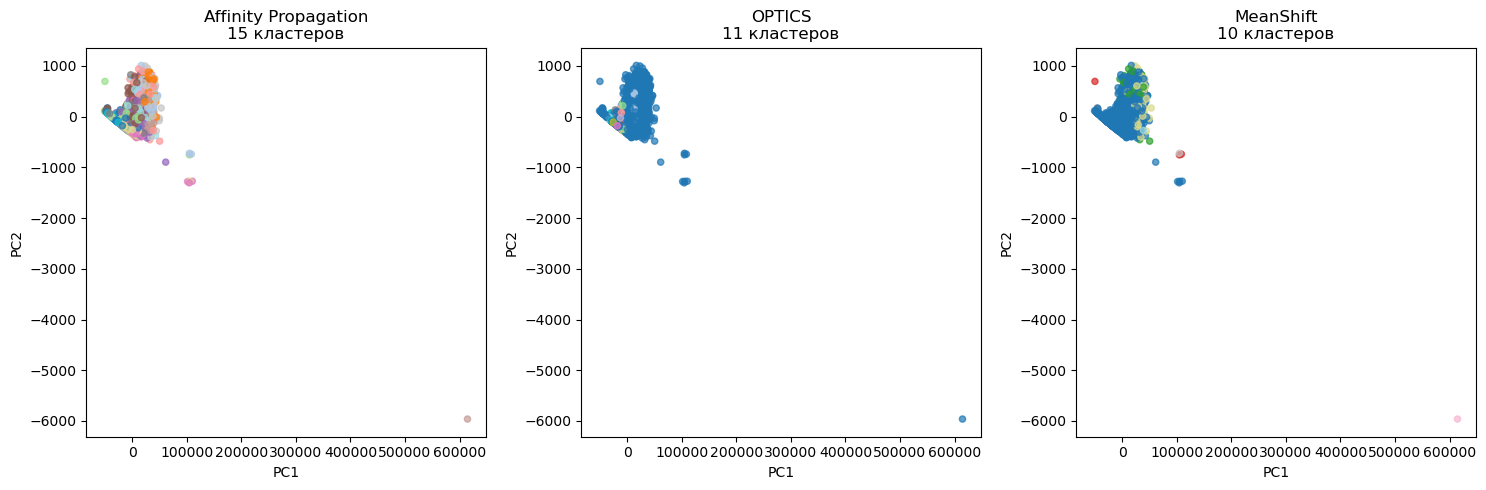

In [83]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Создаем 3 графика рядом
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

pca = PCA(n_components=2)
df_pca = pca.fit_transform(df)

scatter1 = axes[0].scatter(df_pca[:, 0], df_pca[:, 1], 
                          c=affinity_propagation.labels_, cmap='tab20', alpha=0.7, s=20)
axes[0].set_title(f'Affinity Propagation\n{len(np.unique(affinity_propagation.labels_))} кластеров')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

optics_labels = optics.labels_
scatter2 = axes[1].scatter(df_pca[:, 0], df_pca[:, 1], 
                          c=optics_labels, cmap='tab20', alpha=0.7, s=20)
n_clusters_optics = len(set(optics_labels)) - (1 if -1 in optics_labels else 0)
axes[1].set_title(f'OPTICS\n{n_clusters_optics} кластеров')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

scatter3 = axes[2].scatter(df_pca[:, 0], df_pca[:, 1], 
                          c=clusters, cmap='tab20', alpha=0.7, s=20)
axes[2].set_title(f'MeanShift\n{len(np.unique(clusters))} кластеров')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

for ax in axes:
    ax.ticklabel_format(style='plain', axis='both') 

plt.tight_layout()
plt.show()

Как можно заметить, при имеющемся объеме данных и количестве признаков, распределения на кластеры визуально трудно различимы, так как плотность наблюдений очень большая. Не смотря на проблемы с визуализацией, при работе с данными customer_segmentation, для получения наиболее точных результатов лучше использовать метод Affinity Propagation. 